
# Macroeconomía España vs. Unión Europea (World Bank API)




## 1) Requisitos
Ejecuta esta celda si necesitas instalar dependencias.


In [ ]:

# %pip install pandas requests matplotlib



## 2) Imports y configuración


In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

START_YEAR = 1990
END_YEAR = 2025
COUNTRIES = ["ESP", "EUU"]  # España y Unión Europea (agregado WB)
BASE_URL = "https://api.worldbank.org/v2/country/{countries}/indicator/{indicator}?date={start}:{end}&format=json&per_page=25000"

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")



## 3) Mapa de indicadores (World Bank codes)


In [ ]:
INDICATORS = {
    "GDP (current US$) (billions)": ("NY.GDP.MKTP.CD",lambda s: s / 1e9),
    "PIB real (US$ constantes)": ("NY.GDP.MKTP.KD", None),
    "Consumo privado (% del PIB)":("NE.CON.PRVT.ZS", None),
    "GDP per capita, PPP (constant 2017 international $)": ("NY.GDP.PCAP.PP.KD", None),
    "GDP growth (annual %)": ("NY.GDP.MKTP.KD.ZG", None),
    "Desempleo (% de la población activa)": ("SL.UEM.TOTL.ZS", None),
    "Población activa (personas)": ("SL.TLF.TOTL.IN", None),
    "Migrantes internacionales (% población)": ("SM.POP.TOTL.ZS", None),
    "Formación bruta de capital (% del PIB)": ("NE.GDI.TOTL.ZS", None),
    "Formación bruta de capital privado (% del PIB)": ("NE.GDI.FPRV.ZS", None),
    "Gasto Público (% of GDP)": ("NE.CON.GOVT.ZS", None),
    "Inflation, GDP deflator (annual %)": ("NY.GDP.DEFL.KD.ZG", None),
    "Agriculture, forestry, and fishing, value added (% of GDP)": ("NV.AGR.TOTL.ZS", None),
    "Industry (including construction), value added (% of GDP)": ("NV.IND.TOTL.ZS", None),
    "Exports of goods and services (% of GDP)": ("NE.EXP.GNFS.ZS", None),
    "Imports of goods and services (% of GDP)": ("NE.IMP.GNFS.ZS", None),
    "Revenue, excluding grants (% of GDP)": ("GC.REV.XGRT.GD.ZS", None),
    "Central government debt, total (% of GDP)": ("GC.DOD.TOTL.GD.ZS", None),
    "Central government debt, total (current US$)": ("GC.DOD.TOTL.CN", lambda s: s / 1e9),
    "Net lending (+) / net borrowing (-) (% of GDP)": ("GC.NLD.TOTL.GD.ZS", None),
    "Domestic credit provided by financial sector (% of GDP)": ("FS.AST.DOMS.GD.ZS", None),
    "Tax revenue (% of GDP)": ("GC.TAX.TOTL.GD.ZS", None),
    "Military expenditure (% of GDP)": ("MS.MIL.XPND.GD.ZS", None),
    "Mobile cellular subscriptions (per 100 people)": ("IT.CEL.SETS.P2", None),
    "Individuals using the Internet (% of population)": ("IT.NET.USER.ZS", None),
    "High-technology exports (% of manufactured exports)": ("TX.VAL.TECH.MF.ZS", None),
}



## 4) Funciones auxiliares


In [ ]:
import warnings
from requests import HTTPError

EU_ALTERNATIVES = ["EUU", "EU27_2020", "EU28"]  # WB aggregates (según indicador/periodo)

def fetch_indicator_country(indicator_code, country, start=START_YEAR, end=END_YEAR):
    """Descarga un indicador para 1 país/agregado. Devuelve Serie year->value."""
    url = BASE_URL.format(countries=country, indicator=indicator_code, start=start, end=end)
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    data = r.json()
    if not isinstance(data, list) or len(data) < 2 or data[1] is None:
        return pd.Series(dtype=float)
    rows = []
    for rec in data[1]:
        try:
            y = int(rec.get("date"))
            v = rec.get("value")
            if v is not None:
                rows.append((y, float(v)))
        except Exception:
            continue
    if not rows:
        return pd.Series(dtype=float)
    s = pd.Series(dict(rows)).sort_index()
    return s

def fetch_indicator(indicator_code, countries=COUNTRIES, start=START_YEAR, end=END_YEAR):
    """Descarga un indicador para varios países/agregados con tolerancia a 400/404."""
    cols = {}
    for c in countries:
        tried = []
        alts = (EU_ALTERNATIVES if c == "EUU" else [c])
        ok = False
        # 1) probar país/agregado con END_YEAR
        for cc in alts:
            tried.append((cc, start, end))
            try:
                s = fetch_indicator_country(indicator_code, cc, start, end)
                if not s.empty:
                    cols[c] = s  # mantiene etiqueta 'EUU' en columnas aunque usemos 'EU27_2020'
                    ok = True
                    break
            except HTTPError as e:
                # 2) retry recortando al año anterior por si hay corte de actualización
                if end > start:
                    try:
                        s = fetch_indicator_country(indicator_code, cc, start, end-1)
                        if not s.empty:
                            cols[c] = s
                            ok = True
                            break
                    except HTTPError:
                        pass
                continue
        if not ok:
            warnings.warn(f"[omitido] {indicator_code} para {c}. Intentos: {tried}")
    if not cols:
        raise ValueError(f"Sin datos para {indicator_code} en países {countries}")
    # Construir DataFrame (index=year) y columnas por país
    df = pd.DataFrame(cols)
    df.index.name = "year"
    return df

def bulk_fetch(indicators_map=INDICATORS):
    out = {}
    failed = []
    for human_name, (code, transform) in indicators_map.items():
        try:
            df = fetch_indicator(code)
            if transform is not None:
                df = df.apply(transform)
            out[human_name] = df
        except Exception as e:
            failed.append((human_name, code, str(e)))
    if failed:
        print("Indicadores omitidos por error:")
        for name, code, msg in failed:
            print(f"  - {name} [{code}]: {msg}")
    return out

def to_wide_panel(indicator_frames):
    frames = []
    for ind_name, df in indicator_frames.items():
        df2 = df.copy()
        df2.columns = pd.MultiIndex.from_product([[ind_name], df2.columns])
        frames.append(df2)
    panel = pd.concat(frames, axis=1).sort_index()
    return panel


## 5) Descarga de datos


In [ ]:
indicator_frames = bulk_fetch(INDICATORS)
panel = to_wide_panel(indicator_frames)
panel.tail()

/tmp/ipykernel_4689/1972992619.py:57: UserWarning: [omitido] NE.GDI.FPRV.ZS para ESP. Intentos: [('ESP', 1990, 2025)]
  warnings.warn(f"[omitido] {indicator_code} para {c}. Intentos: {tried}")
/tmp/ipykernel_4689/1972992619.py:57: UserWarning: [omitido] NE.GDI.FPRV.ZS para EUU. Intentos: [('EUU', 1990, 2025), ('EU27_2020', 1990, 2025), ('EU28', 1990, 2025)]
  warnings.warn(f"[omitido] {indicator_code} para {c}. Intentos: {tried}")
/tmp/ipykernel_4689/1972992619.py:57: UserWarning: [omitido] GC.DOD.TOTL.GD.ZS para EUU. Intentos: [('EUU', 1990, 2025), ('EU27_2020', 1990, 2025), ('EU28', 1990, 2025)]
  warnings.warn(f"[omitido] {indicator_code} para {c}. Intentos: {tried}")
/tmp/ipykernel_4689/1972992619.py:57: UserWarning: [omitido] GC.DOD.TOTL.CN para EUU. Intentos: [('EUU', 1990, 2025), ('EU27_2020', 1990, 2025), ('EU28', 1990, 2025)]
  warnings.warn(f"[omitido] {indicator_code} para {c}. Intentos: {tried}")
/tmp/ipykernel_4689/1972992619.py:57: UserWarning: [omitido] FS.AST.DOMS.GD.ZS

Indicadores omitidos por error:
  - Formación bruta de capital privado (% del PIB) [NE.GDI.FPRV.ZS]: Sin datos para NE.GDI.FPRV.ZS en países ['ESP', 'EUU']
  - Domestic credit provided by financial sector (% of GDP) [FS.AST.DOMS.GD.ZS]: Sin datos para FS.AST.DOMS.GD.ZS en países ['ESP', 'EUU']


/tmp/ipykernel_4689/1972992619.py:57: UserWarning: [omitido] IT.NET.USER.ZS para EUU. Intentos: [('EUU', 1990, 2025), ('EU27_2020', 1990, 2025), ('EU28', 1990, 2025)]
  warnings.warn(f"[omitido] {indicator_code} para {c}. Intentos: {tried}")


GDP (current US$) (billions)           PIB real (US$ constantes)  \
                              ESP       EUU                       ESP   
year                                                                    
2021                     1,461.24 17,495.26      1,267,004,457,826.92   
2022                     1,448.85 17,023.62      1,347,716,659,731.45   
2023                     1,619.48 18,659.28      1,380,882,052,539.27   
2024                     1,725.67 19,501.08      1,428,595,035,672.37   
2025                     1,906.45 21,243.21      1,468,952,188,359.05   

                           Consumo privado (% del PIB)        \
                       EUU                         ESP   EUU   
year                                                           
2021 14,943,314,673,230.50                       56.14 51.13   
2022 15,475,977,359,466.40                       56.39 52.64   
2023 15,543,763,521,524.00                       55.42 52.70   
2024 15,712,658,769,407.30                       55.36 52.67   
2025 15,954,312,288,194.70                       55.56 52.58   

     GDP per capita, PPP (constant 2017 international $)            \
                                                     ESP       EUU   
year                                                                 
2021                                          44,251.67  51,968.44   
2022                                          46,733.48  53,777.33   
2023                                          47,322.59  53,861.80   
2024                                          48,460.29  54,341.63   
2025                                          49,318.11  55,086.99   

     GDP growth (annual %)       ...  \
                       ESP  EUU  ...   
year                             ...   
2021                  6.68 6.38  ...   
2022                  6.37 3.56  ...   
2023                  2.46 0.44  ...   
2024                  3.46 1.09  ...   
2025                  2.82 1.54  ...   

     Net lending (+) / net borrowing (-) (% of GDP) Tax revenue (% of GDP)  \
                                                EUU                    ESP   
year                                                                         
2021                                          -4.81                  14.88   
2022                                          -3.33                  15.47   
2023                                          -3.14                  15.00   
2024                                          -2.74                  14.93   
2025                                            NaN                    NaN   

           Military expenditure (% of GDP)       \
       EUU                             ESP  EUU   
year                                              
2021 19.95                            1.37 1.49   
2022 19.93                            1.43 1.52   
2023 19.63                            1.53 1.64   
2024 19.78                            1.46 1.85   
2025   NaN                            2.13 2.18   

     Mobile cellular subscriptions (per 100 people)         \
                                                ESP    EUU   
year                                                         
2021                                         119.00 123.27   
2022                                         123.40 123.69   
2023                                         127.72    NaN   
2024                                         130.26    NaN   
2025                                            NaN    NaN   

     Individuals using the Internet (% of population)  \
                                                  ESP   
year                                                    
2021                                            93.90   
2022                                            94.49   
2023                                            95.45   
2024                                            95.76   
2025                                              NaN   

     High-technology exports (% of ma


## 6) Guardar CSVs


In [ ]:
panel_csv = save_csvs(indicator_frames, panel_path="wb_spain_eu_panel.csv")
panel_csv


'wb_spain_eu_panel.csv'

# ESTRUCTURA DEL PIB

La **formación bruta de capital** mide la inversión total en activos fijos dentro de una economía durante un período determinado.
Incluye la inversión en maquinaria, equipos, infraestructuras, edificios, vivienda y variaciones en inventarios.


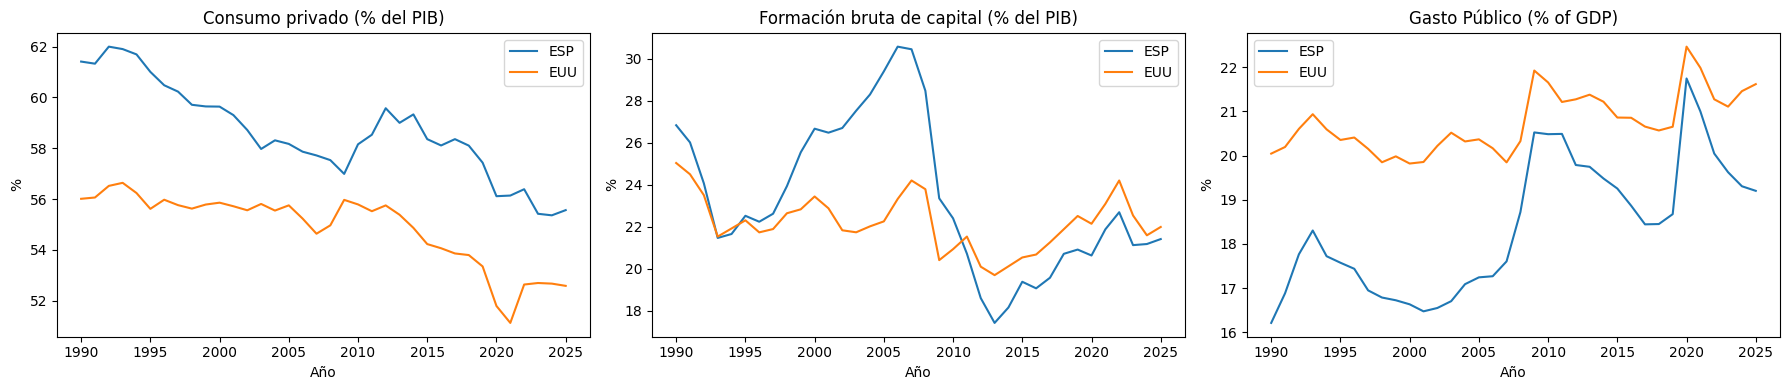

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# 1. Consumo privado
indicator_frames["Consumo privado (% del PIB)"].plot(
    ax=axes[0],
    title="Consumo privado (% del PIB)"
)
axes[0].set_xlabel("Año")
axes[0].set_ylabel("%")

# 2. Formación bruta de capital
indicator_frames["Formación bruta de capital (% del PIB)"].plot(
    ax=axes[1],
    title="Formación bruta de capital (% del PIB)"
)
axes[1].set_xlabel("Año")
axes[1].set_ylabel("%")

# 3. Consumo público
indicator_frames["Gasto Público (% of GDP)"].plot(
    ax=axes[2],
    title="Gasto Público (% of GDP)"
)
axes[2].set_xlabel("Año")
axes[2].set_ylabel("%")

plt.tight_layout()
plt.show()

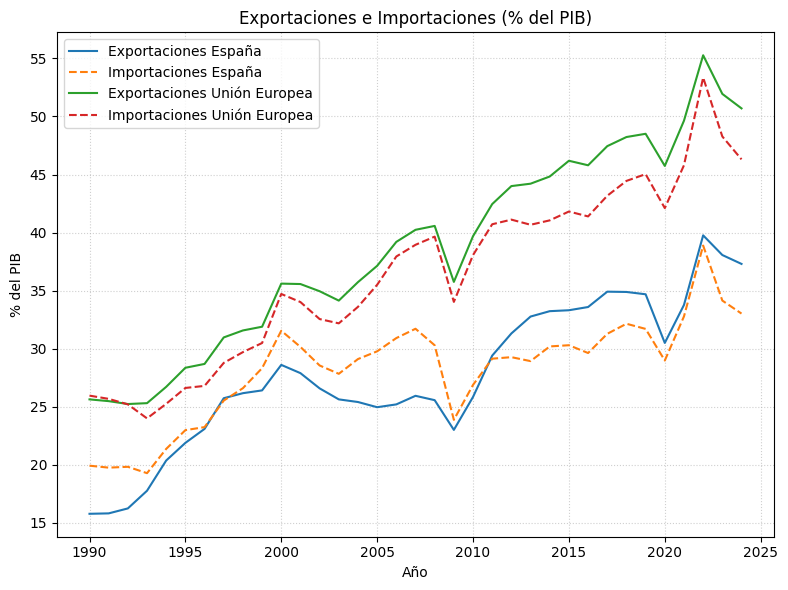

In [ ]:
# Gráfico de Exportaciones vs. Importaciones (% del PIB)
exp = indicator_frames["Exports of goods and services (% of GDP)"]
imp = indicator_frames["Imports of goods and services (% of GDP)"]

fig, ax = plt.subplots(figsize=(8, 6))

for country, label in [("ESP", "España"), ("EUU", "Unión Europea")]:
    ax.plot(exp.index, exp[country], label=f"Exportaciones {label}")
    ax.plot(imp.index, imp[country], linestyle="--", label=f"Importaciones {label}")

ax.set_title("Exportaciones e Importaciones (% del PIB)")
ax.set_xlabel("Año")
ax.set_ylabel("% del PIB")
ax.legend()
ax.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

No disponemos de datos de la formación bruta de capital en WB, por eso recurrimos a Eurostat

In [ ]:
!pip install eurostat

In [ ]:
import eurostat

# Descargar la tabla de Eurostat
df = eurostat.get_data_df("sdg_08_11")

# Examinar las categorías disponibles
print(df.columns.tolist())
print(df.head())

['freq', 'unit', 'indic', 'geo\\TIME_PERIOD', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
  freq unit    indic geo\TIME_PERIOD  2000  2001  2002  2003  2004  2005  ...  \
0    A   PC  INV_BSN              AT 16.25 16.13 15.11 16.08 15.77 14.93  ...   
1    A   PC  INV_BSN              BE 14.38 14.91 13.52 13.24 14.07 14.09  ...   
2    A   PC  INV_BSN              BG 12.44 14.84 15.07 16.07 17.06 20.75  ...   
3    A   PC  INV_BSN              CH 19.07 18.77 19.14 18.31 18.93 19.01  ...   
4    A   PC  INV_BSN              CY  8.69  7.78  8.97  6.76  6.14  6.27  ...   

   2016  2017  2018  2019  2020  2021  2022  2023  2024  2025  
0 14.80 15.05 15.40 16.06 15.67 15.78 15.44 15.31 14.10   NaN  
1 15.23 15.20 15.29 15.67 15.36 15.23 15.47 15.77 16.00   NaN  
2 12.59 13.75 13.43 12.86 13.22 11.46 12.30   NaN   NaN   NaN  
3 1

In [ ]:
# 1. Descargar los datos
df = eurostat.get_data_df("sdg_08_11")

# 2. Identificar la columna geográfica
col_geo = next(c for c in df.columns if c.startswith("geo"))

df = df.rename(columns={col_geo: "geo"})

# 3. Seleccionar España y Unión Europea
df = df[
    df["geo"].isin(["ES", "EU27_2020"]) &
    df["indic"].isin(["INV_BSN", "INV_HH", "INV_GOV"])
].copy()

# 4. Convertir los años en filas
columnas_anios = [
    c for c in df.columns
    if str(c).isdigit() and 2000 <= int(c) <= 2025
]

df = df.melt(
    id_vars=["geo", "indic"],
    value_vars=columnas_anios,
    var_name="Año",
    value_name="Valor"
)

df["Año"] = df["Año"].astype(int)
df["Valor"] = pd.to_numeric(df["Valor"], errors="coerce")

# 5. Organizar las variables
df = df.pivot_table(
    index=["Año", "geo"],
    columns="indic",
    values="Valor"
).reset_index()

# Inversión privada = empresas + hogares
df["Inversión privada"] = df["INV_BSN"] + df["INV_HH"]
df["Inversión pública"] = df["INV_GOV"]

# 6. Crear los DataFrames
inversion_espana = (
    df[df["geo"] == "ES"]
    .set_index("Año")[["Inversión privada", "Inversión pública"]]
)

inversion_ue = (
    df[df["geo"] == "EU27_2020"]
    .set_index("Año")[["Inversión privada", "Inversión pública"]]
)


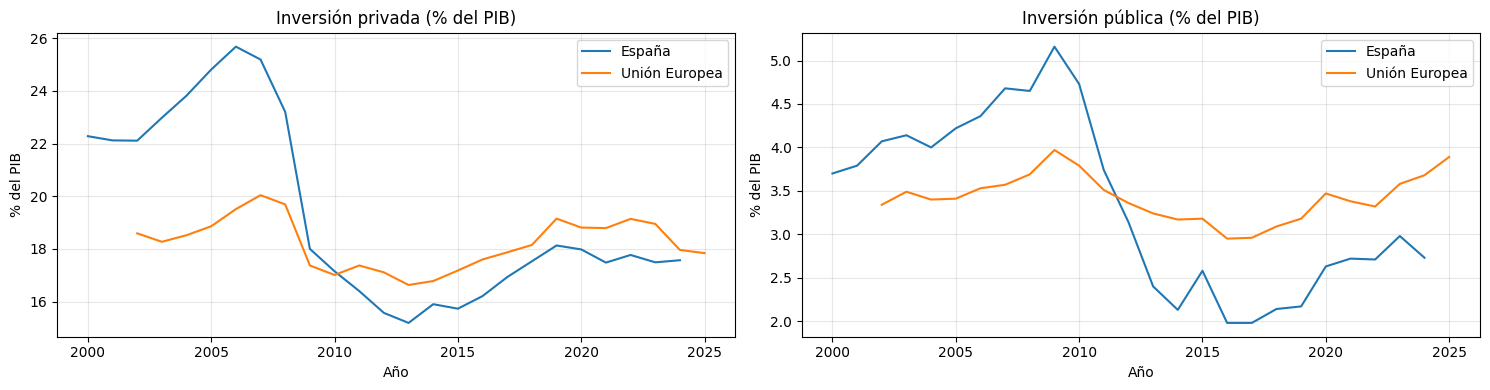

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# 1. Inversión privada: España vs UE
axes[0].plot(
    inversion_espana.index,
    inversion_espana["Inversión privada"],
    label="España"
)

axes[0].plot(
    inversion_ue.index,
    inversion_ue["Inversión privada"],
    label="Unión Europea"
)

axes[0].set_title("Inversión privada (% del PIB)")
axes[0].set_xlabel("Año")
axes[0].set_ylabel("% del PIB")
axes[0].legend()
axes[0].grid(alpha=0.3)


# 2. Inversión pública: España vs UE
axes[1].plot(
    inversion_espana.index,
    inversion_espana["Inversión pública"],
    label="España"
)

axes[1].plot(
    inversion_ue.index,
    inversion_ue["Inversión pública"],
    label="Unión Europea"
)

axes[1].set_title("Inversión pública (% del PIB)")
axes[1].set_xlabel("Año")
axes[1].set_ylabel("% del PIB")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Análisis del PIB desde el enfoque de rentas

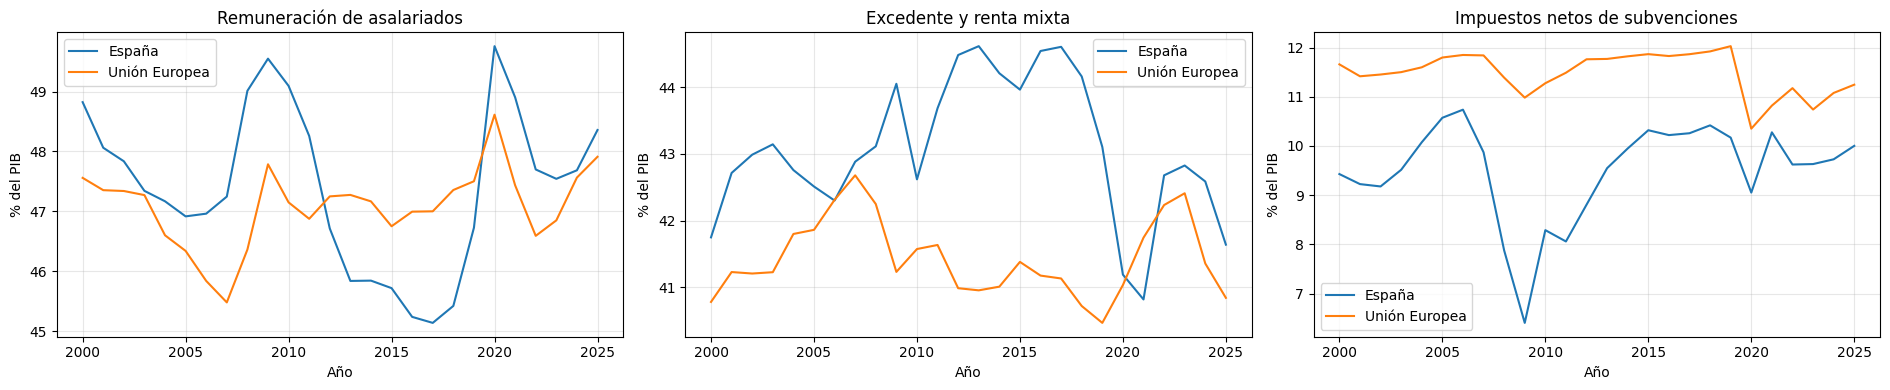

In [ ]:
# 1. Indicadores de contabilidad nacional
indicadores = {
    "B1GQ": "PIB",
    "D1": "Remuneración de asalariados",
    "B2A3G": "Excedente y renta mixta"
}

# 2. Descargar datos de España y UE
df = eurostat.get_data_df(
    "nama_10_gdp",
    filter_pars={
        "geo": ["ES", "EU27_2020"],
        "unit": "CP_MEUR",
        "na_item": list(indicadores.keys()),
        "startPeriod": 2000,
        "endPeriod": 2025
    }
)

# 3. Preparar los datos
col_geo = next(c for c in df.columns if c.startswith("geo"))
df = df.rename(columns={col_geo: "geo"})

anios = [c for c in df.columns if str(c).isdigit()]

df = df.melt(
    id_vars=["geo", "na_item"],
    value_vars=anios,
    var_name="Año",
    value_name="Valor"
)

df["Año"] = df["Año"].astype(int)
df["Valor"] = pd.to_numeric(df["Valor"], errors="coerce")

df["Variable"] = df["na_item"].map(indicadores)

df = df.pivot_table(
    index=["Año", "geo"],
    columns="Variable",
    values="Valor"
).reset_index()

# Comprobar que se han descargado las tres series
faltantes = set(indicadores.values()) - set(df.columns)
if faltantes:
    raise ValueError(f"Faltan series en Eurostat: {faltantes}")

# 4. Calcular los porcentajes del PIB
df["Salarios"] = (
    100 * df["Remuneración de asalariados"] / df["PIB"]
)

df["Excedente y renta mixta (%)"] = (
    100 * df["Excedente y renta mixta"] / df["PIB"]
)

# Impuestos netos como componente residual
df["Impuestos netos"] = (
    100 - df["Salarios"] - df["Excedente y renta mixta (%)"]
)

# 5. Separar España y UE
espana = df[df["geo"] == "ES"].set_index("Año")
ue = df[df["geo"] == "EU27_2020"].set_index("Año")

# 6. Gráficos comparativos
variables = [
    ("Salarios", "Remuneración de asalariados"),
    ("Excedente y renta mixta (%)", "Excedente y renta mixta"),
    ("Impuestos netos", "Impuestos netos de subvenciones")
]

fig, axes = plt.subplots(1, 3, figsize=(19, 4))

for ax, (variable, titulo) in zip(axes, variables):

    ax.plot(espana.index, espana[variable], label="España")
    ax.plot(ue.index, ue[variable], label="Unión Europea")

    ax.set_title(titulo)
    ax.set_xlabel("Año")
    ax.set_ylabel("% del PIB")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

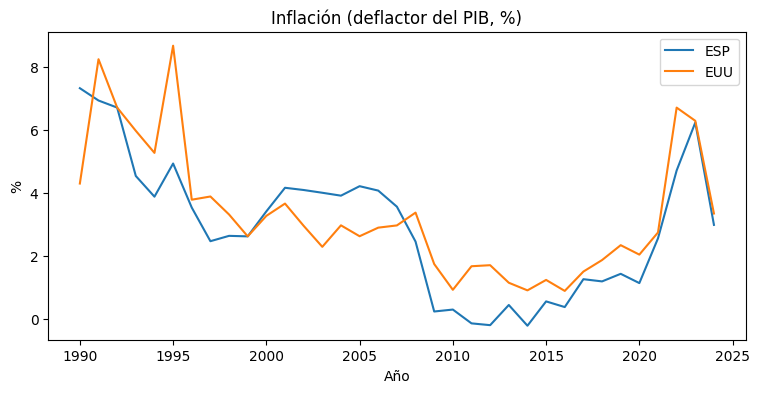

In [ ]:
ax = indicator_frames["Inflation, GDP deflator (annual %)"].plot(figsize=(9,4), title="Inflación (deflactor del PIB, %)")
ax.set_xlabel("Año"); ax.set_ylabel("%")
plt.show()

# Crecimiento económico

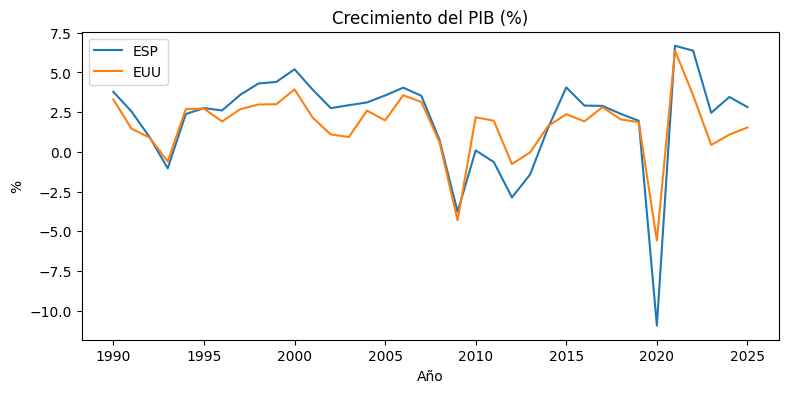

In [ ]:
ax = indicator_frames["GDP growth (annual %)"].plot(figsize=(9,4), title="Crecimiento del PIB (%)")
ax.set_xlabel("Año"); ax.set_ylabel("%")
plt.show()




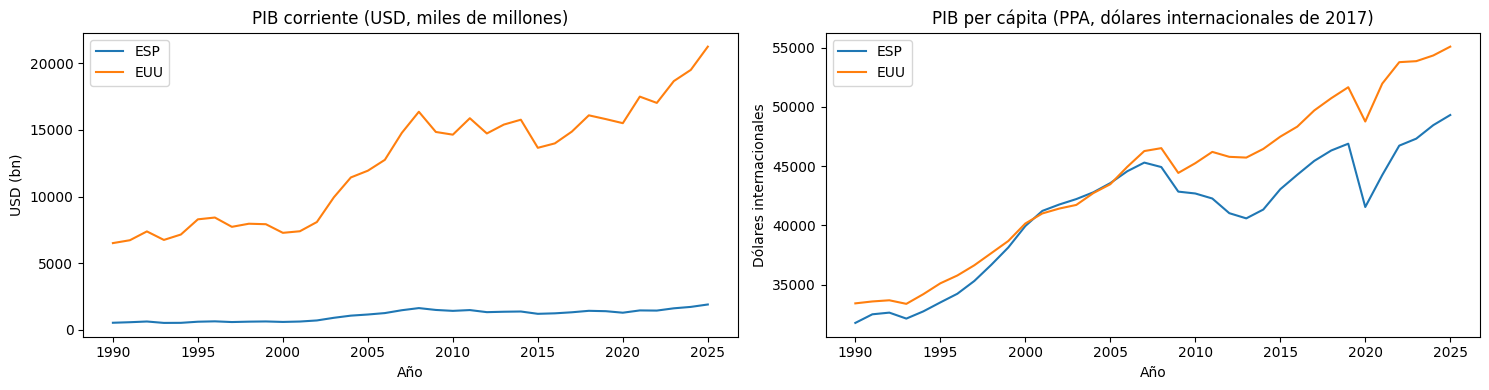

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# 1. PIB nominal
indicator_frames["GDP (current US$) (billions)"].plot(
    ax=axes[0],
    title="PIB corriente (USD, miles de millones)"
)
axes[0].set_xlabel("Año")
axes[0].set_ylabel("USD (bn)")

# 2. PIB per cápita ajustado por PPA
indicator_frames["GDP per capita, PPP (constant 2017 international $)"].plot(
    ax=axes[1],
    title="PIB per cápita (PPA, dólares internacionales de 2017)"
)
axes[1].set_xlabel("Año")
axes[1].set_ylabel("Dólares internacionales")

plt.tight_layout()
plt.show()


# Factor trabajo

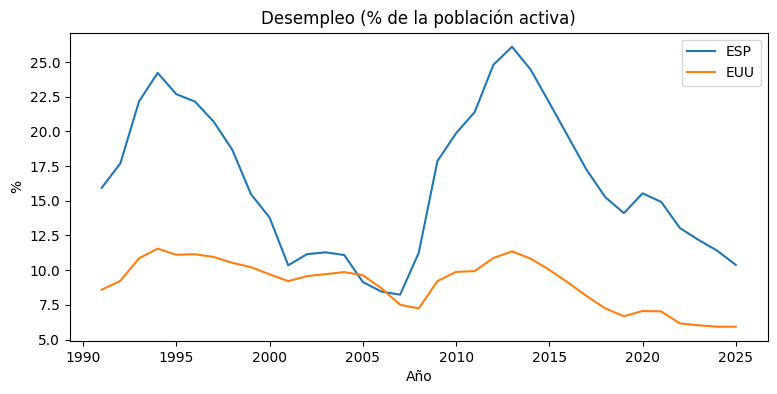

In [ ]:
ax = indicator_frames["Desempleo (% de la población activa)"].plot(figsize=(9,4), title="Desempleo (% de la población activa)")
ax.set_xlabel("Año"); ax.set_ylabel("%")
plt.show()


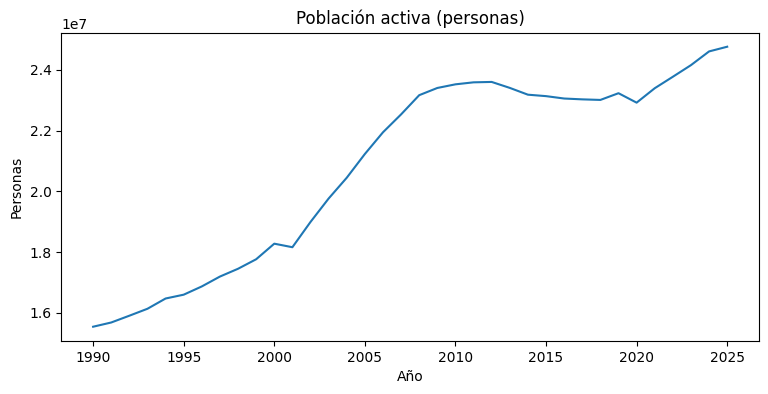

In [ ]:
ax = indicator_frames["Población activa (personas)"]["ESP"].plot(figsize=(9,4), title="Población activa (personas)")
ax.set_xlabel("Año"); ax.set_ylabel("Personas")
plt.show()

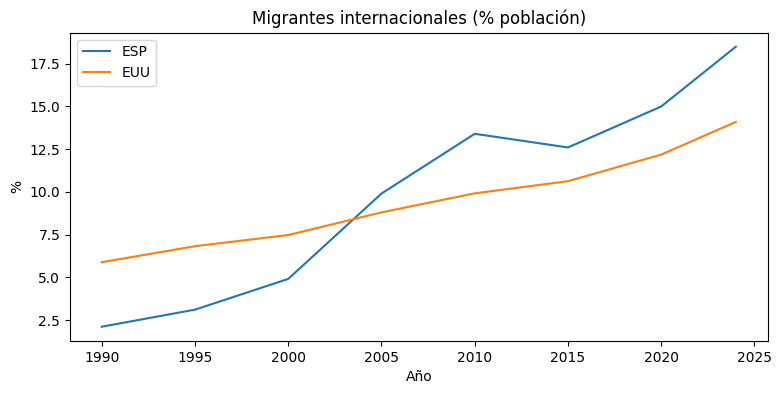

In [ ]:
ax = indicator_frames["Migrantes internacionales (% población)"].plot(figsize=(9,4), title="Migrantes internacionales (% población)")
ax.set_xlabel("Año"); ax.set_ylabel("%")
plt.show()

$$PIB=\frac{PIB}{Ocupados}\times \frac{Ocupados}{Activos}\times Activos$$

In [ ]:
# 1. Extraer datos de España
pib = indicator_frames["PIB real (US$ constantes)"]["ESP"]
activos = indicator_frames["Población activa (personas)"]["ESP"]
desempleo = indicator_frames[ "Desempleo (% de la población activa)"]["ESP"]

# 2. Unificar series temporales
df = pd.concat(
    [pib, activos, desempleo],
    axis=1
)

df.columns = ["PIB", "Activos", "Desempleo"]
df = df.dropna().sort_index()

# 3. Calcular los tres componentes
df["Ocupados"] = df["Activos"] * (1 - df["Desempleo"] / 100)

df["Productividad"] = df["PIB"] / df["Ocupados"]

df["Proporción ocupados"] = df["Ocupados"] / df["Activos"] * 100

df["Población activa (millones)"] = df["Activos"] / 1e6

# 4. Comprobar la identidad contable
df["PIB reconstruido"] = (
    df["Productividad"]
    * df["Proporción ocupados"] / 100
    * df["Activos"]
)

print(df.tail())



                      PIB       Activos  Desempleo      Ocupados  \
year                                                               
2021 1,267,004,457,826.92 23,392,854.00      14.91 19,904,043.75   
2022 1,347,716,659,731.45 23,770,575.00      13.03 20,672,555.96   
2023 1,380,882,052,539.27 24,153,349.00      12.18 21,211,712.63   
2024 1,428,595,035,672.37 24,604,513.00      11.40 21,799,598.52   
2025 1,468,952,188,359.05 24,759,183.00      10.38 22,190,170.17   

      Productividad  Proporción ocupados  Población activa (millones)  \
year                                                                    
2021      63,655.63                85.09                        23.39   
2022      65,193.52                86.97                        23.77   
2023      65,099.98                87.82                        24.15   
2024      65,533.09                88.60                        24.60   
2025      66,198.33                89.62                        24.76   

         PI

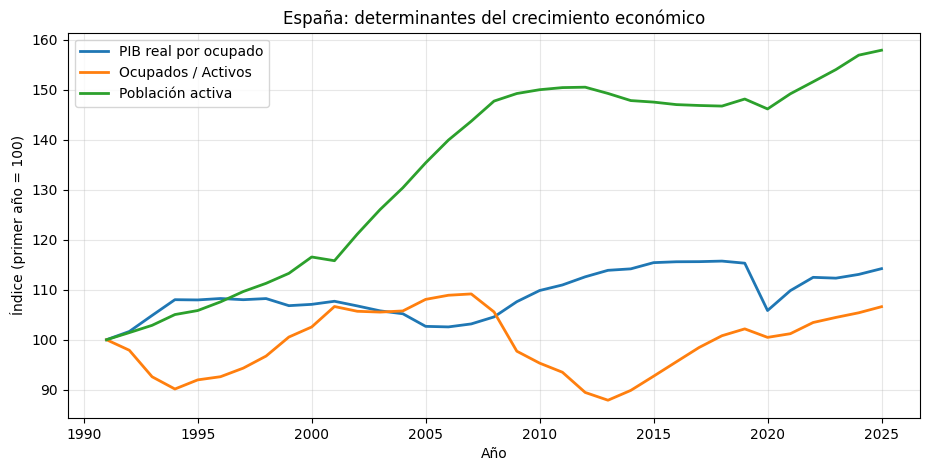

In [ ]:
variables = [
    "Productividad",
    "Proporción ocupados",
    "Activos"
]

# Convertir todas las series en índices base 100
indices = df[variables].div(df[variables].iloc[0]).mul(100)

ax = indices.plot(
    figsize=(11, 5),
    linewidth=2,
    title="España: determinantes del crecimiento económico"
)

ax.set_xlabel("Año")
ax.set_ylabel("Índice (primer año = 100)")
ax.grid(alpha=0.3)
ax.legend([
    "PIB real por ocupado",
    "Ocupados / Activos",
    "Población activa"
])

plt.show()

$$\Delta lnPIB=\Delta ln \text{Productividad factor trabajo}+\Delta ln Desempleo+ \Delta ln Activos$$

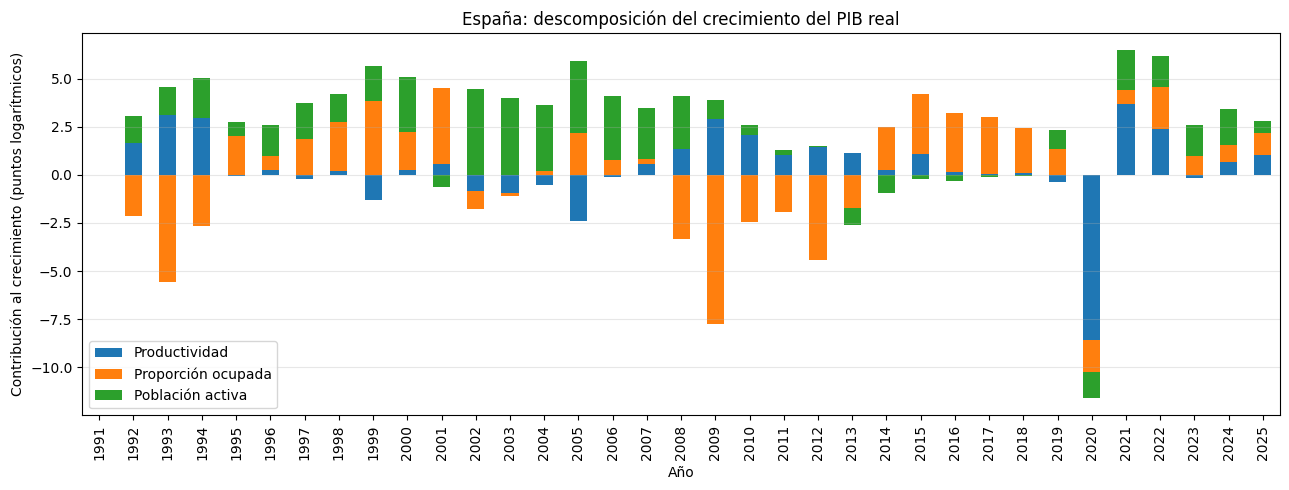

In [ ]:
contribuciones = np.log(
    df[["Productividad", "Proporción ocupados", "Activos"]]
).diff() * 100

contribuciones.columns = [
    "Productividad",
    "Proporción ocupada",
    "Población activa"
]

ax = contribuciones.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 5),
    title="España: descomposición del crecimiento del PIB real"
)

ax.set_ylabel("Contribución al crecimiento (puntos logarítmicos)")
ax.set_xlabel("Año")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

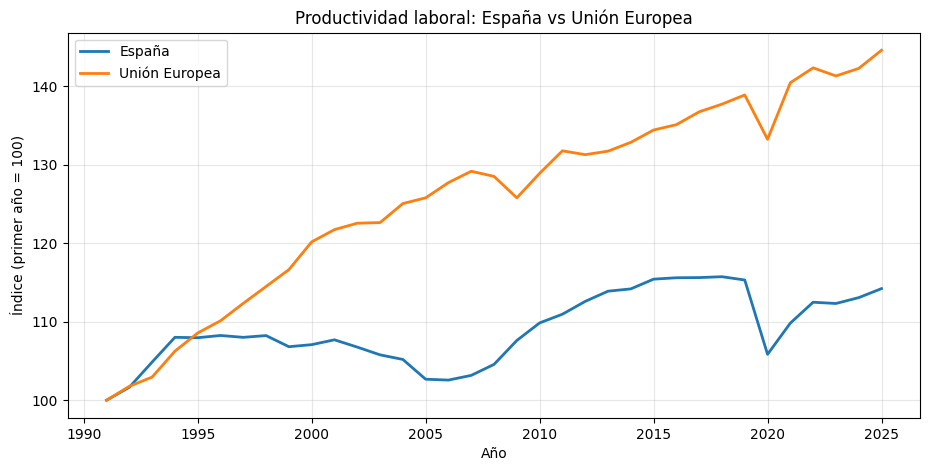

In [ ]:
pib = indicator_frames["PIB real (US$ constantes)"]
activos = indicator_frames["Población activa (personas)"]
desempleo = indicator_frames["Desempleo (% de la población activa)"]

paises = ["ESP", "EUU"]

# Número de personas ocupadas
ocupados = activos[paises] * (1 - desempleo[paises] / 100)

# Productividad laboral: PIB real por ocupado
productividad = pib[paises] / ocupados

productividad = productividad.dropna().sort_index()

# Índice base 100 en el primer año común
productividad_indice = (
    productividad / productividad.iloc[0] * 100
)

ax = productividad_indice.plot(
    figsize=(11, 5),
    linewidth=2,
    title="Productividad laboral: España vs Unión Europea"
)

ax.set_xlabel("Año")
ax.set_ylabel("Índice (primer año = 100)")
ax.legend(["España", "Unión Europea"])
ax.grid(alpha=0.3)

plt.show()

# Salario Mínimo (Eurostat)

In [ ]:
pip install eurostat

In [ ]:
import eurostat

# Descargar salarios mínimos de Eurostat
df = eurostat.get_data_df("earn_mw_cur")

# Filtrar valores en paridad de poder adquisitivo
df = df[(df["currency"] == "PPS") & (df["freq"] == "S")]

# Países de la UE con salario mínimo legal nacional
ue = [
    "BE", "BG", "CZ", "DE", "EE", "IE", "EL",
    "ES", "FR", "HR", "CY", "LV", "LT", "LU",
    "HU", "MT", "NL", "PL", "PT", "RO",
    "SI", "SK"
]

# Identificar columna geográfica
col_geo = [c for c in df.columns if "geo" in c.lower()][0]

df = df[df[col_geo].isin(ue)]

# Convertir de formato ancho a largo
df = df.melt(
    id_vars=[col_geo, "currency", "freq"],
    var_name="Periodo",
    value_name="SMI"
)

df["SMI"] = pd.to_numeric(df["SMI"], errors="coerce")

# Utilizar datos de enero de cada año
df = df[df["Periodo"].str.endswith("-S1")].copy()
df["Año"] = df["Periodo"].str[:4].astype(int)

# España
espana = df[df[col_geo] == "ES"].set_index("Año")["SMI"]

# Media de países de la UE con datos disponibles
media_ue = df.groupby("Año")["SMI"].mean()

# Unificar
salarios = pd.concat([espana, media_ue], axis=1)
salarios.columns = ["España", "Media UE"]
salarios = salarios.dropna().sort_index()

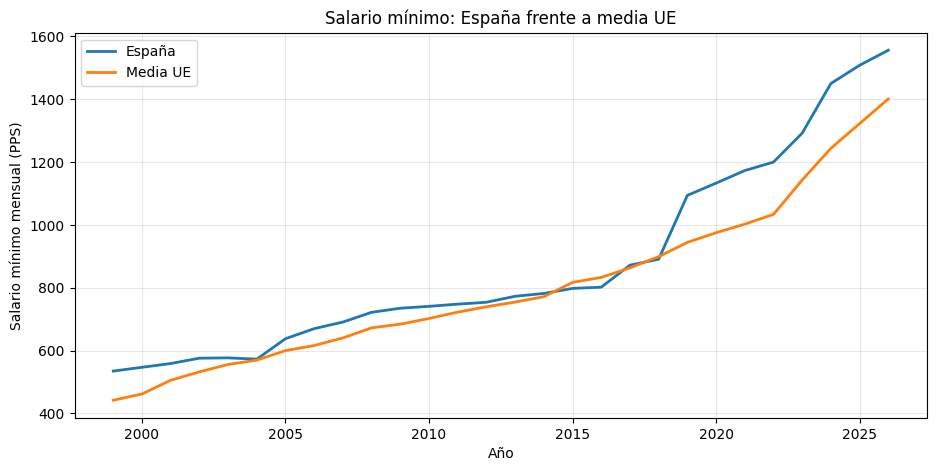

In [ ]:
ax = salarios.plot(
    figsize=(11, 5),
    linewidth=2,
    title="Salario mínimo: España frente a media UE"
)

ax.set_xlabel("Año")
ax.set_ylabel("Salario mínimo mensual (PPS)")
ax.grid(alpha=0.3)

plt.show()

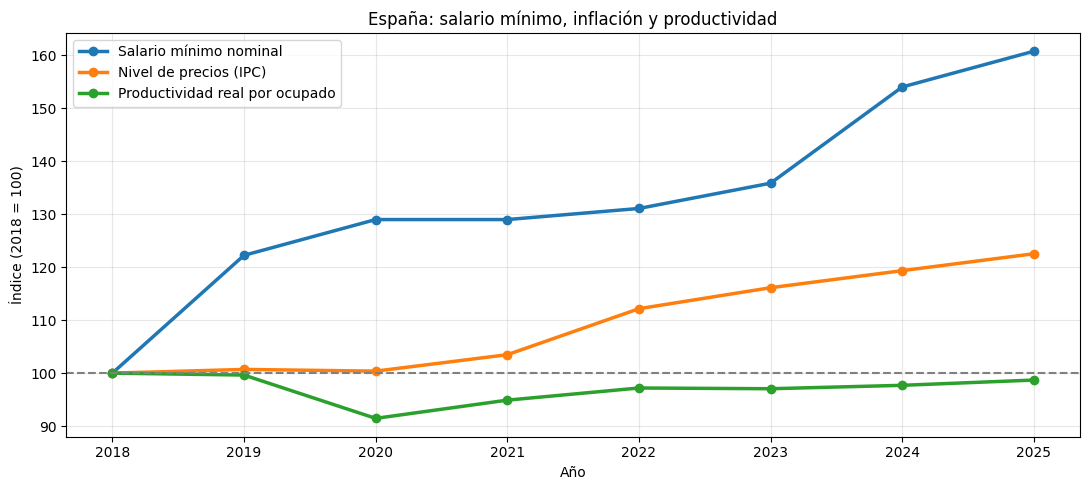

In [ ]:
import requests

# ------------------------------------
# 1. SALARIO MÍNIMO NOMINAL - EUROSTAT
# ------------------------------------

smi = eurostat.get_data_df("earn_mw_cur")

# Seleccionar España y salarios en euros
col_geo = [c for c in smi.columns if "geo" in c.lower()][0]

smi = smi[
    (smi[col_geo] == "ES") &
    (smi["currency"] == "EUR")
]

# Seleccionar enero de cada año (S1)
columnas = [
    c for c in smi.columns
    if str(c).endswith("-S1")
]

smi = smi[columnas].T
smi.index = smi.index.str[:4].astype(int)

smi = pd.to_numeric(smi.iloc[:, 0], errors="coerce")
smi.name = "Salario mínimo nominal"


# ------------------------------------
# 2. DESCARGAR DATOS BANCO MUNDIAL
# ------------------------------------

def descargar_wb(indicador):
    url = (
        f"https://api.worldbank.org/v2/country/ESP/"
        f"indicator/{indicador}"
    )

    respuesta = requests.get(
        url,
        params={"format": "json", "per_page": 2000},
        timeout=30
    )
    respuesta.raise_for_status()

    datos = respuesta.json()[1]

    serie = pd.Series({
        int(d["date"]): d["value"]
        for d in datos if d["value"] is not None
    })

    return serie.sort_index()


# Índice de precios de consumo
ipc = descargar_wb("FP.CPI.TOTL")

# PIB real por ocupado (PPA constantes)
productividad = descargar_wb("SL.GDP.PCAP.EM.KD")


# ------------------------------------
# 3. COMBINAR LOS INDICADORES
# ------------------------------------

df = pd.concat(
    [smi, ipc, productividad],
    axis=1
)

df.columns = [
    "Salario mínimo",
    "IPC",
    "Productividad laboral"
]

df = df.loc[2018:].dropna().sort_index()

# Comprobar que existe el año base
if 2018 not in df.index:
    raise ValueError("No hay datos completos para 2018")

# Índices base 2018 = 100
indices = df.div(df.loc[2018]).mul(100)


# ------------------------------------
# 4. REPRESENTAR LOS RESULTADOS
# ------------------------------------

ax = indices.plot(
    figsize=(11, 5),
    linewidth=2.5,
    marker="o",
    title="España: salario mínimo, inflación y productividad"
)

ax.axhline(100, color="gray", linestyle="--")

ax.set_xlabel("Año")
ax.set_ylabel("Índice (2018 = 100)")
ax.legend([
    "Salario mínimo nominal",
    "Nivel de precios (IPC)",
    "Productividad real por ocupado"
])

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# FORMACIÓN BRUTA DE CAPTIAL

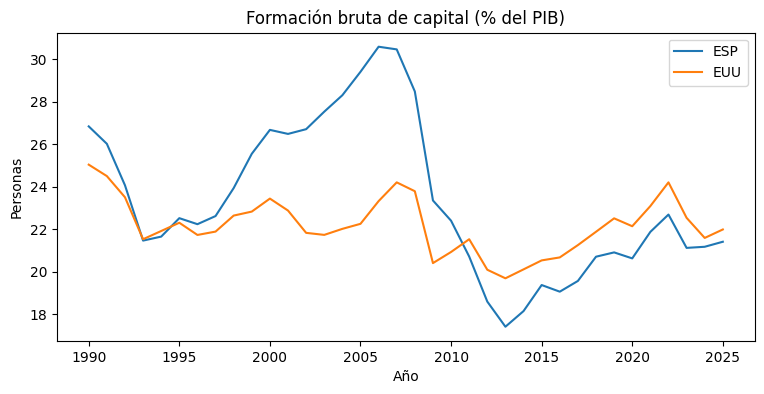

In [ ]:
ax = indicator_frames["Formación bruta de capital (% del PIB)"].plot(figsize=(9,4), title="Formación bruta de capital (% del PIB)")
ax.set_xlabel("Año"); ax.set_ylabel("Personas")
plt.show()




Unidades: ['CLV05_MEUR' 'CLV05_MNAC' 'CLV10_MEUR' 'CLV10_MNAC' 'CLV15_MEUR'
 'CLV15_MNAC' 'CLV20_MEUR' 'CLV20_MNAC' 'CLV_I05' 'CLV_I10' 'CLV_I15'
 'CLV_I20' 'CLV_PCH_PRE' 'CON_PPCH_PRE' 'CP_MEUR' 'CP_MNAC'
 'PC_EU27_2020_MEUR_CP' 'PC_GDP' 'PC_TOT' 'PD05_EUR' 'PD05_NAC' 'PD10_EUR'
 'PD10_NAC' 'PD15_EUR' 'PD15_NAC' 'PD20_EUR' 'PD20_NAC' 'PD_PCH_PRE_EUR'
 'PD_PCH_PRE_NAC' 'PYP_MEUR' 'PYP_MNAC']
Unidad seleccionada: CLV20_MEUR


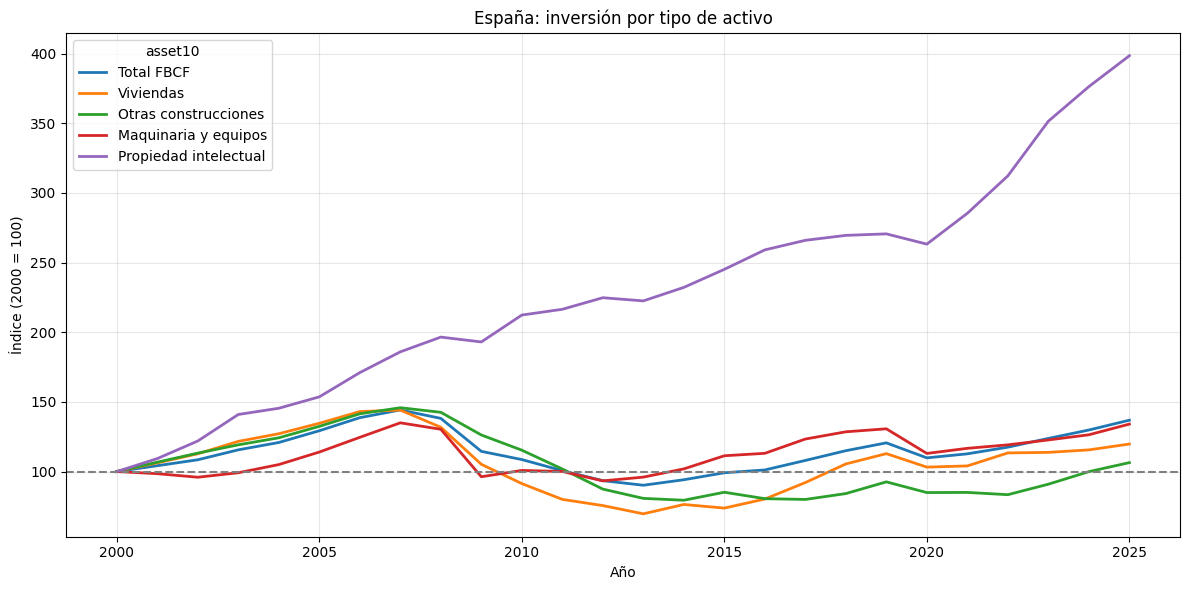

In [ ]:
import eurostat

# 1. Descargar datos de Eurostat
df = eurostat.get_data_df("nama_10_an6")

# 2. Examinar las unidades disponibles
print("Unidades:", df["unit"].unique())

# 3. Seleccionar España y volúmenes encadenados
unidades = [u for u in df["unit"].unique()
            if u.startswith("CLV") and u.endswith("_MEUR")]

unidad = max(unidades, key=lambda x: int(x[3:5]))
print("Unidad seleccionada:", unidad)

df = df[
    (df["geo\\TIME_PERIOD"] == "ES") &
    (df["unit"] == unidad) &
    (df["freq"] == "A")
].copy()

# 4. Tipos de activos
activos = {
    "N11G": "Total FBCF",
    "N111G": "Viviendas",
    "N112G": "Otras construcciones",
    "N11MG": "Maquinaria y equipos",
    "N117G": "Propiedad intelectual"
}

df = df[df["asset10"].isin(activos.keys())]

# 5. Pasar los datos a formato largo
df = df.melt(
    id_vars=["freq", "unit", "asset10", "geo\\TIME_PERIOD"],
    var_name="Año",
    value_name="Inversión"
)

df["Año"] = pd.to_numeric(df["Año"], errors="coerce")
df["Inversión"] = pd.to_numeric(df["Inversión"], errors="coerce")

# 6. Crear DataFrame con años y activos
inversion = df.pivot_table(
    index="Año",
    columns="asset10",
    values="Inversión"
)

inversion = inversion.rename(columns=activos)
inversion = inversion.sort_index()

# 7. Índice base 100 en 2000
base = 2000

columnas = [
    "Total FBCF",
    "Viviendas",
    "Otras construcciones",
    "Maquinaria y equipos",
    "Propiedad intelectual"
]

inversion = inversion[columnas]

indices = (
    inversion.loc[base:]
    .div(inversion.loc[base])
    .mul(100)
)

# 8. Gráfico
ax = indices.plot(
    figsize=(12, 6),
    linewidth=2,
    title="España: inversión por tipo de activo"
)

ax.axhline(100, color="gray", linestyle="--")

ax.set_xlabel("Año")
ax.set_ylabel("Índice (2000 = 100)")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

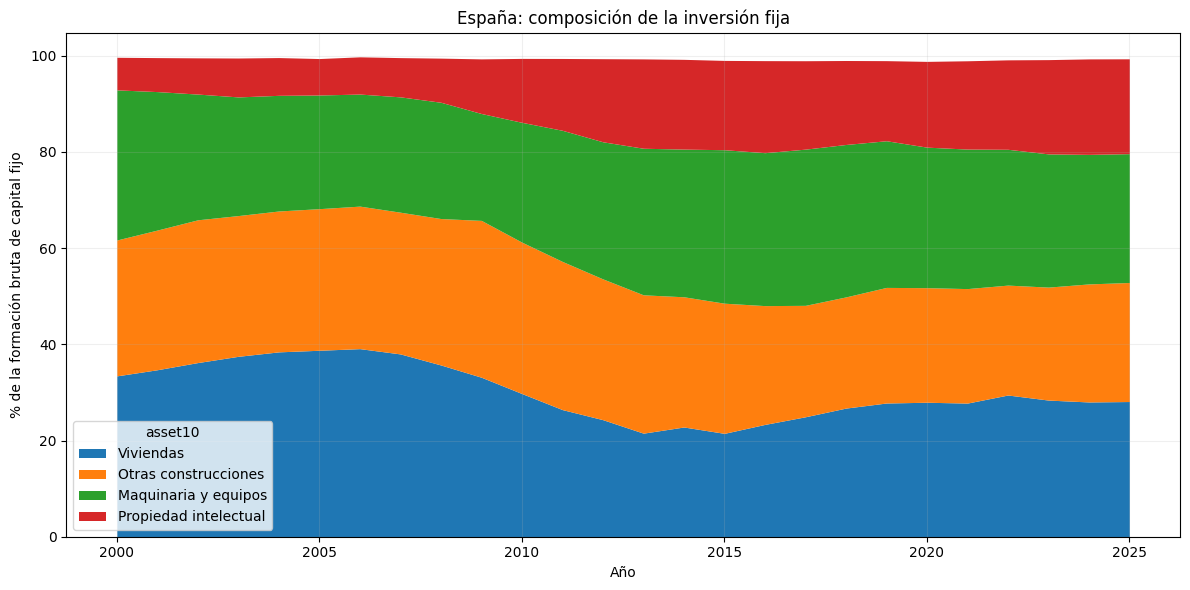

In [ ]:
# Descargar datos nominales
df_nom = eurostat.get_data_df("nama_10_an6")

df_nom = df_nom[
    (df_nom["geo\\TIME_PERIOD"] == "ES") &
    (df_nom["unit"] == "CP_MEUR") &
    (df_nom["freq"] == "A") &
    (df_nom["asset10"].isin(activos.keys()))
]

df_nom = df_nom.melt(
    id_vars=["freq", "unit", "asset10", "geo\\TIME_PERIOD"],
    var_name="Año",
    value_name="Inversión"
)

df_nom["Año"] = pd.to_numeric(df_nom["Año"], errors="coerce")
df_nom["Inversión"] = pd.to_numeric(
    df_nom["Inversión"], errors="coerce"
)

composicion = df_nom.pivot_table(
    index="Año",
    columns="asset10",
    values="Inversión"
).rename(columns=activos)

componentes = [
    "Viviendas",
    "Otras construcciones",
    "Maquinaria y equipos",
    "Propiedad intelectual"
]

participaciones = (
    composicion[componentes]
    .div(composicion["Total FBCF"], axis=0)
    .mul(100)
)

ax = participaciones.loc[2000:].plot.area(
    figsize=(12, 6),
    title="España: composición de la inversión fija",
    linewidth=0
)

ax.set_ylabel("% de la formación bruta de capital fijo")
ax.set_xlabel("Año")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

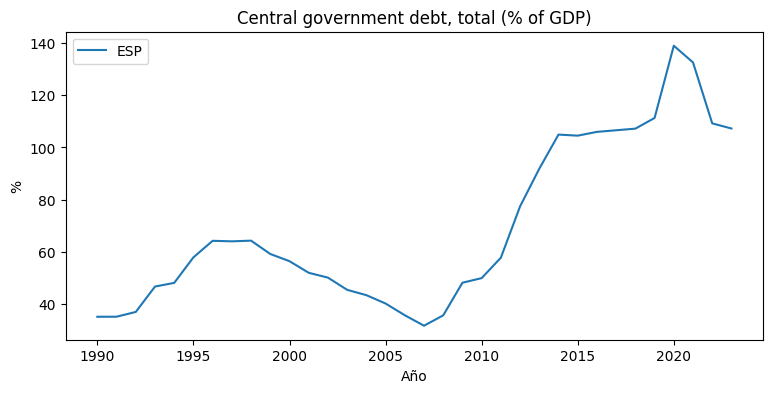

In [ ]:
# Deuda pública
ax = indicator_frames["Central government debt, total (% of GDP)"].plot(figsize=(9,4), title="Central government debt, total (% of GDP)")
ax.set_xlabel("Año"); ax.set_ylabel("%")
plt.show()

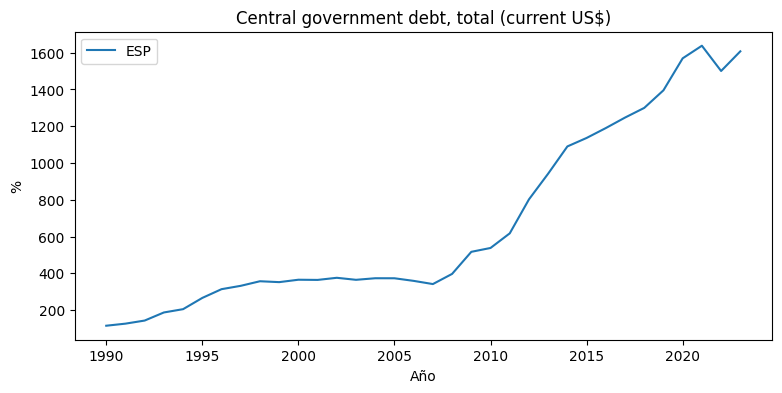

In [ ]:
# Deuda pública
ax = indicator_frames["Central government debt, total (current US$)"].plot(figsize=(9,4), title= "Central government debt, total (current US$)")
ax.set_xlabel("Año"); ax.set_ylabel("%")
plt.show()

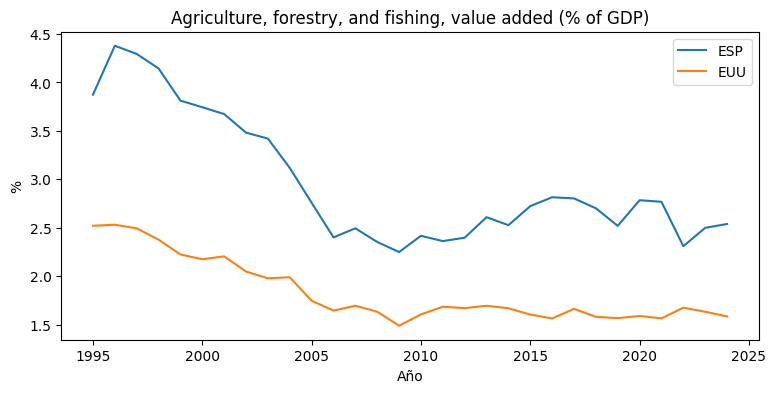

In [ ]:
ax = indicator_frames["Agriculture, forestry, and fishing, value added (% of GDP)"].plot(figsize=(9,4), title="Agriculture, forestry, and fishing, value added (% of GDP)")
ax.set_xlabel("Año"); ax.set_ylabel("%")
plt.show()

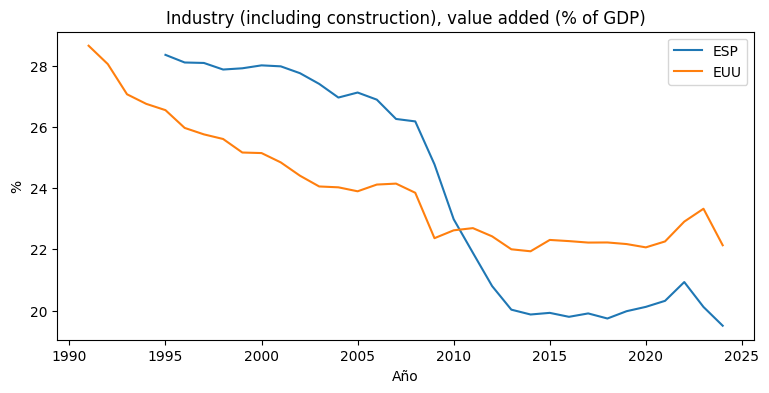

In [ ]:
ax = indicator_frames["Industry (including construction), value added (% of GDP)"].plot(figsize=(9,4), title="Industry (including construction), value added (% of GDP)")
ax.set_xlabel("Año"); ax.set_ylabel("%")
plt.show()

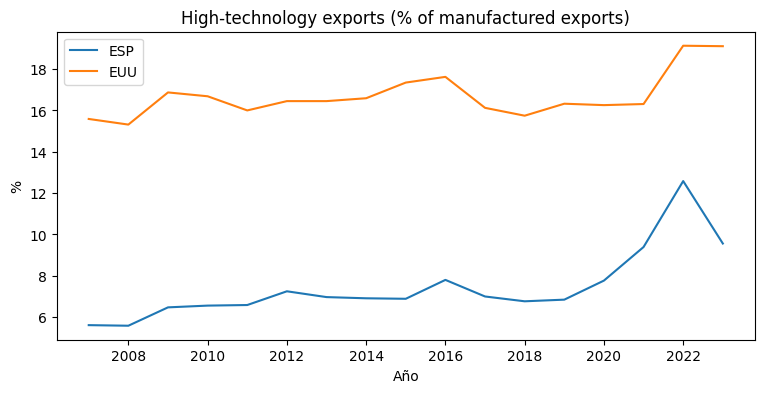

In [ ]:
ax = indicator_frames["High-technology exports (% of manufactured exports)"].plot(figsize=(9,4), title= "High-technology exports (% of manufactured exports)")
ax.set_xlabel("Año"); ax.set_ylabel("%")
plt.show()

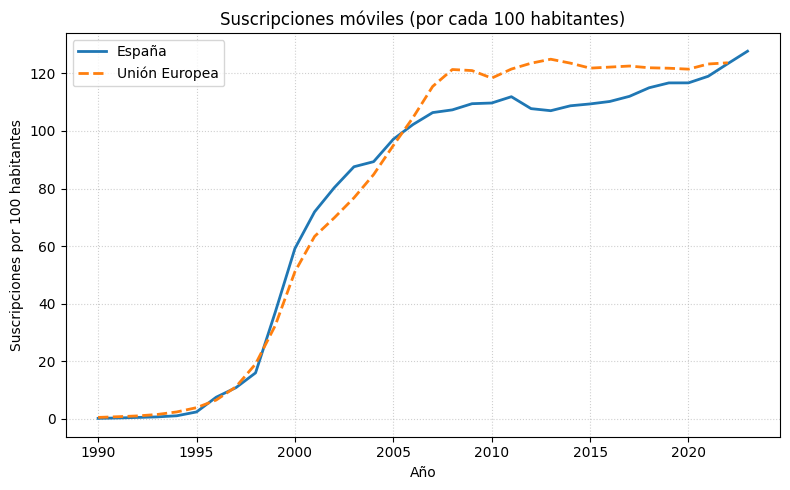

In [ ]:
# Digitalización de la economía

mobile = indicator_frames["Mobile cellular subscriptions (per 100 people)"]

fig, ax = plt.subplots(figsize=(8,5))
ax.plot(mobile.index, mobile["ESP"], label="España", linewidth=2)
ax.plot(mobile.index, mobile["EUU"], label="Unión Europea", linewidth=2, linestyle="--")

ax.set_title("Suscripciones móviles (por cada 100 habitantes)")
ax.set_xlabel("Año")
ax.set_ylabel("Suscripciones por 100 habitantes")
ax.legend()
ax.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

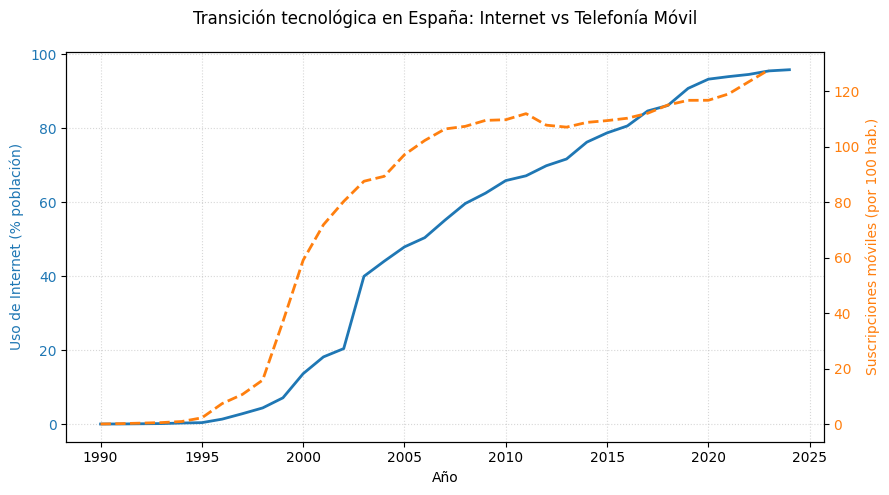

In [ ]:
# Gráfico combinado: uso de Internet vs suscripciones móviles (España)
internet = indicator_frames["Individuals using the Internet (% of population)"]
mobile   = indicator_frames["Mobile cellular subscriptions (per 100 people)"]

fig, ax1 = plt.subplots(figsize=(9,5))

color1 = "tab:blue"
ax1.set_xlabel("Año")
ax1.set_ylabel("Uso de Internet (% población)", color=color1)
ax1.plot(internet.index, internet["ESP"], color=color1, linewidth=2, label="Internet (% población)")
ax1.tick_params(axis='y', labelcolor=color1)

# Eje secundario para suscripciones móviles
ax2 = ax1.twinx()
color2 = "tab:orange"
ax2.set_ylabel("Suscripciones móviles (por 100 hab.)", color=color2)
ax2.plot(mobile.index, mobile["ESP"], color=color2, linewidth=2, linestyle="--", label="Móvil (por 100 hab.)")
ax2.tick_params(axis='y', labelcolor=color2)

# Estilo general
fig.suptitle("Transición tecnológica en España: Internet vs Telefonía Móvil", fontsize=12)
fig.tight_layout()
ax1.grid(True, linestyle=":", alpha=0.5)
plt.show()